# ADP 18회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: adp_18_summary.pdf pp.1~11; 기존 주제 모음 대조

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'18회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 고객 등급 예측

유통사는 독립 고객 500명의 구매 특성으로 5개 등급을 예측하려 한다. id는 예측에서 제외하고 아래 비교에서 같은 학습·검증·시험 구간을 사용한다.

자료: customers.csv

### 1-1

결측·극단값과 구매 특성을 탐색하고 구매당 금액·거래 빈도·상대 최근성 등 파생변수 3개를 설계하시오. 분모가 0인 경우와 전처리 적합 범위를 명시하시오.

**판단 및 풀이 근거**

구매당 금액·거래 빈도·상대 최근성으로 정의합니다. 0분모를 명시적으로 방어하며 결측 대치·표준화는 fit 내부에서 적합합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

               id        days    duration       count        amount      grade
count  500.000000  500.000000  500.000000  500.000000    480.000000  500.00000
mean   249.500000  185.766000  369.960000   25.270000   1442.881663    3.00000
std    144.481833  104.176161  219.137694   13.990445   1325.550201    1.41563
min      0.000000    2.000000    2.000000    1.000000    210.043112    1.00000
25%    124.750000   96.750000  184.000000   14.000000    658.852542    2.00000
50%    249.500000  182.000000  375.500000   25.500000   1147.984473    3.00000
75%    374.250000  280.000000  560.250000   37.000000   1731.627532    4.00000
max    499.000000  364.000000  728.000000   49.000000  15234.107872    5.00000
id           0
days         0
duration     0
count        0
amount      20
grade        0
dtype: int64


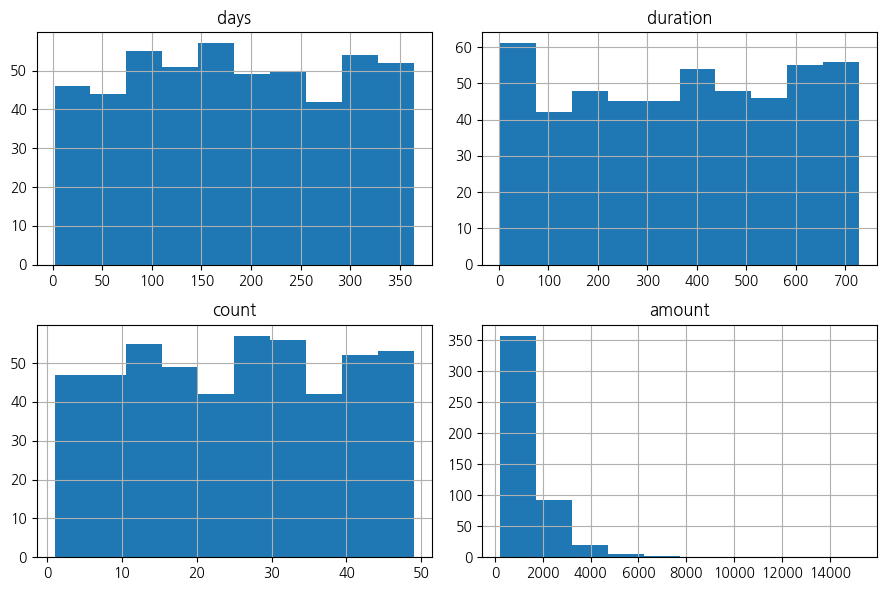

   days  duration  count  ...  mean_purchase  purchase_frequency  recency_ratio
0    91       494     16  ...      42.956945            0.032389       0.184211
1   245       218     40  ...      14.136976            0.183486       1.123853
2    97       692     23  ...      75.459978            0.033237       0.140173
3   148       202      3  ...     705.782675            0.014851       0.732673
4   258       278     43  ...      35.831071            0.154676       0.928058

[5 rows x 7 columns]
fit/valid/test: 262 88 150


In [2]:
set_question('1-1')
customers=load('customers.csv');print(customers.describe());print(customers.isna().sum())
customers.drop(columns=['id','grade']).hist(figsize=(9,6));plt.tight_layout();plt.show()
X=customers.drop(columns=['id','grade']).copy();y=customers.grade
X['mean_purchase']=X.amount/X['count'].clip(lower=1)
X['purchase_frequency']=X['count']/X.duration.clip(lower=1)
X['recency_ratio']=X.days/X.duration.clip(lower=1)
train,test=train_test_split(np.arange(len(y)),test_size=.3,random_state=1234,stratify=y)
fit,valid=train_test_split(train,test_size=.25,random_state=1234,stratify=y.iloc[train])
print(X.head());print('fit/valid/test:',len(fit),len(valid),len(test))

### 1-2

유사 고객을 4×4 격자로 요약한 뒤 학습 고객의 등급 분포를 매핑하는 예측 방안을 구현하시오. 빈 격자 처리와 확률 생성 근거, validation macro F1·등급별 ROC를 제시하시오.

**판단 및 풀이 근거**

SOM 본체는 비지도입니다. 각 BMU의 학습 라벨 빈도에 전체 학습 prior 1개를 더해 빈 격자도 처리합니다. validation 라벨은 격자 매핑에 사용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

{'validation_macro_F1': 0.32911505817684306, 'OvR_macro_AUC': 0.7371911205796873}


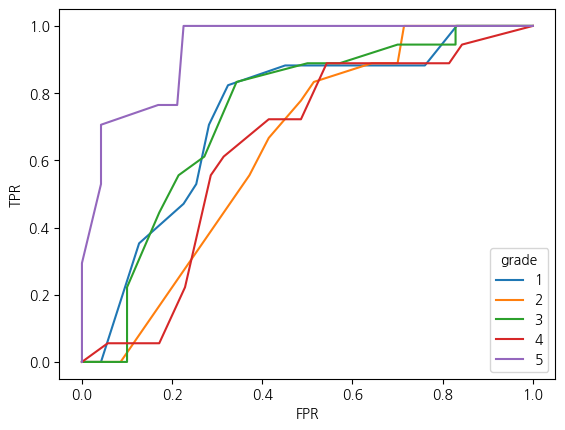

In [3]:
set_question('1-2')
from src.MachineLearning.Decomposition.som import run_som
from sklearn.metrics import roc_auc_score
imputer=SimpleImputer(strategy='median').fit(X.iloc[fit]);fit_X=imputer.transform(X.iloc[fit]);valid_X=imputer.transform(X.iloc[valid])
som=run_som(fit_X,overrides={'rows':4,'columns':4,'n_iter':800})
train_bmu=som.model.transform(fit_X).astype(int);valid_bmu=som.model.transform(valid_X).astype(int)
classes=np.array([1,2,3,4,5]);global_counts=np.array([(y.iloc[fit]==c).sum() for c in classes],float)
prior=global_counts/global_counts.sum();cell_prob={}
for row in range(4):
    for col in range(4):
        mask=(train_bmu[:,0]==row)&(train_bmu[:,1]==col)
        counts=np.array([(y.iloc[fit].to_numpy()[mask]==c).sum() for c in classes],float)
        cell_prob[(row,col)]=(counts+prior)/(counts.sum()+1.)
probs=np.array([cell_prob[tuple(cell)] for cell in valid_bmu]);pred=classes[probs.argmax(axis=1)]
print({'validation_macro_F1':f1_score(y.iloc[valid],pred,average='macro'),'OvR_macro_AUC':roc_auc_score(y.iloc[valid],probs,multi_class='ovr',labels=classes)})
for i,c in enumerate(classes):
    fpr,tpr,_=roc_curve((y.iloc[valid]==c).astype(int),probs[:,i]);plt.plot(fpr,tpr,label=str(c))
plt.legend(title='grade');plt.xlabel('FPR');plt.ylabel('TPR');plt.show()

### 1-3

트리 앙상블·신경망을 포함한 지도 모형 4개를 같은 validation에서 비교하시오. 선정 후보만 train 내부 CV로 튜닝하고 test를 한 번 평가하시오.

**판단 및 풀이 근거**

최종 튜닝의 train은 fit+validation입니다. 모델 선정의 validation 사용과 CV 재적합을 구분하고 test는 최종 단일 평가합니다. 튜닝 개선은 합성 자료에서 보장하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

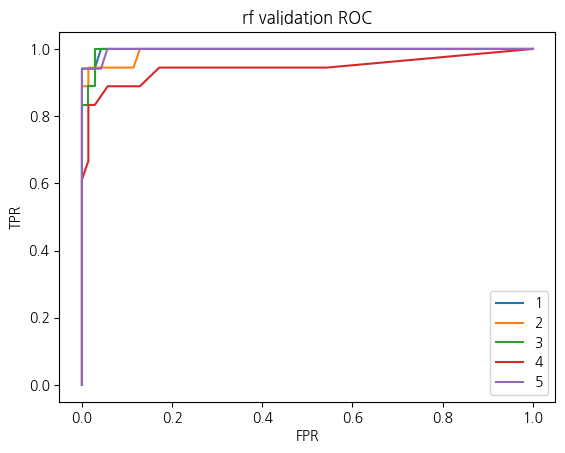

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (400) reached and the optimization hasn't converged yet.
  warnings.warn(


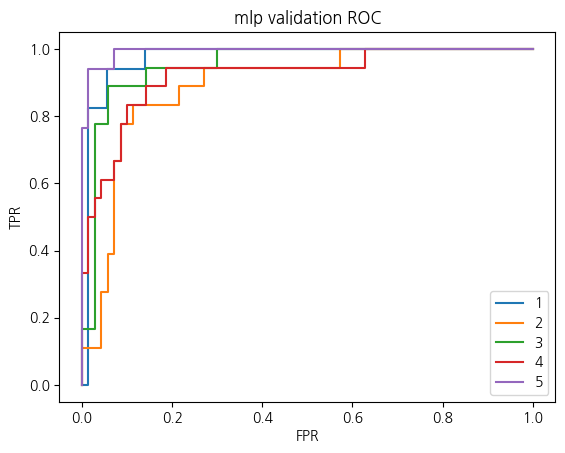

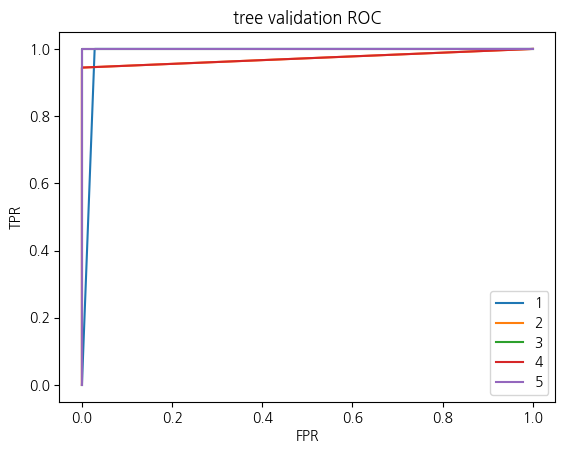

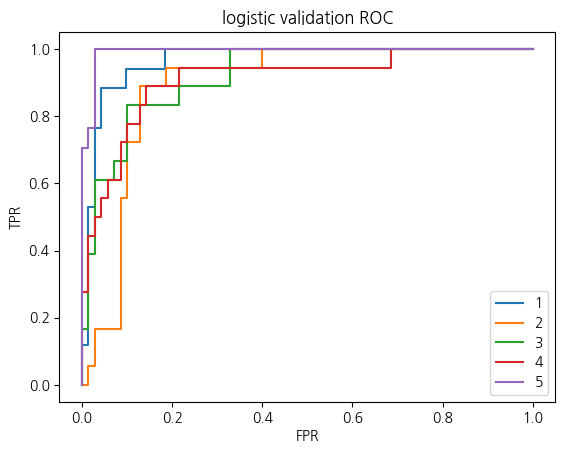

      model        F1       AUC
0        rf  0.908852  0.985434
1       mlp  0.760131  0.946388
2      tree  0.977460  0.986072
3  logistic  0.749985  0.936477
tree {'model__max_depth': 6} {'test_macro_F1': 0.9730886169818316, 'test_OvR_AUC': 0.9906666666666666}


In [4]:
set_question('1-3')
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from src.MachineLearning.Optimization.grid_search import run_grid_search
algorithms={'rf':RandomForestClassifier(n_estimators=40,random_state=1234),'mlp':MLPClassifier(hidden_layer_sizes=(20,),max_iter=400,random_state=1234),'tree':DecisionTreeClassifier(random_state=1234),'logistic':LogisticRegression(max_iter=1000)}
spaces={'rf':{'model__max_depth':[3,6,None]},'mlp':{'model__alpha':[.001,.01]},'tree':{'model__max_depth':[3,6,None]},'logistic':{'model__C':[.1,1.,10.]}}
rows=[]
for name,est in algorithms.items():
    pipe=tabular_pipeline(X,est).fit(X.iloc[fit],y.iloc[fit]);prob=pipe.predict_proba(X.iloc[valid]);pred=pipe.predict(X.iloc[valid])
    rows.append({'model':name,'F1':f1_score(y.iloc[valid],pred,average='macro'),'AUC':roc_auc_score(y.iloc[valid],prob,multi_class='ovr',labels=pipe.classes_)})
    for i,c in enumerate(pipe.classes_):
        fpr,tpr,_=roc_curve((y.iloc[valid]==c).astype(int),prob[:,i]);plt.plot(fpr,tpr,label=str(c))
    plt.title(name+' validation ROC');plt.legend();plt.xlabel('FPR');plt.ylabel('TPR');plt.show()
ranking=pd.DataFrame(rows);print(ranking);winner=ranking.loc[ranking.F1.idxmax(),'model']
tuned=run_grid_search(X.iloc[train],y.iloc[train],tabular_pipeline(X,algorithms[winner]),overrides={'scoring':'f1_macro','search_space':spaces[winner]})
pred=tuned.model.predict(X.iloc[test]);prob=tuned.model.predict_proba(X.iloc[test])
print(winner,tuned.best_params,{'test_macro_F1':f1_score(y.iloc[test],pred,average='macro'),'test_OvR_AUC':roc_auc_score(y.iloc[test],prob,multi_class='ovr',labels=tuned.model.classes_)})
pd.DataFrame({'row_id':test,'actual':y.iloc[test].to_numpy(),'prediction':pred}).to_csv(OUT/'selected_predictions.csv',index=False)

## 2. 고객 의견의 주제

별도 영문 문서와 영문 사전으로 관심 명사를 요약한다. 고객 등급 자료와 독립적인 텍스트 분석 과제다.

자료: english_documents.csv + english_lexicon.csv

### 2-1

소문자 통일·기호 정제·불용어 제외 방안을 적용하시오. 동봉 사전의 명사를 추출해 빈도를 시각화하고 정제·사전의 한계를 설명하시오.

**판단 및 풀이 근거**

원문에 없는 합성 빈도이며 동봉 사전에 명시된 명사만 추출합니다. 실제 원문에는 설치된 영어 POS 모델과 모델 버전을 명시해야 합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

[['customers', 'purchase', 'steel', 'products', 'services'], ['traffic', 'accidents', 'increase', 'rainy', 'seasons'], ['customers', 'compare', 'product', 'prices', 'quality'], ['students', 'analyze', 'traffic', 'customer', 'data']]
         word  count
0   customers      2
1     traffic      2
2       steel      1
3    products      1
4    services      1
5   accidents      1
6     seasons      1
7     product      1
8      prices      1
9     quality      1
10   students      1
11       data      1


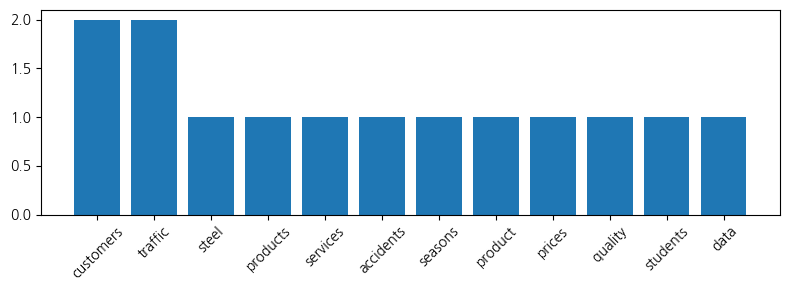

In [5]:
set_question('2-1')
english=load('english_documents.csv');lexicon=load('english_lexicon.csv');stop={'and','the','a','an','during'}
tokens=[[t for t in clean_text(text.lower()).split() if t not in stop] for text in english.text]
vocab=set(lexicon.word);nouns=[[t for t in document if t in vocab] for document in tokens]
print(tokens);word_plot(nouns,12)

## 3. 월별 교통사고 예측

월별 144개 관측에 계절성이 있을 수 있다. 앞 80%만 전처리·진단·후보 선택에 사용하고 마지막 20%는 고정 시점 예측으로 평가한다.

자료: series.csv

### 3-1

시간에 따라 평균 수준이 유지되는지 판단할 방법을 선택하시오. 원자료와 일반·계절 차분 자료의 가설·통계량·p-value·기각 여부를 제시하고 시차 의존성 그림과 함께 해석하시오.

**판단 및 풀이 근거**

수준 안정성을 위해 ADF 단위근 검정을 선택한다. H0: 단위근이 있다, H1: 없다. 수준·일반 차분·계절 차분을 구분하며 기각으로 모든 정상성 조건을 입증하지 않는다.

**계산·해석 상세**

차분한 자료에 ARMA를 적합하거나 원자료에 ARIMA를 적합하는 관점을 구분합니다. 단위근 검정 하나로 모든 정상성 조건을 입증하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

{'ADF_raw': np.float64(0.9761736962268875), 'ADF_diff': np.float64(8.308618992272413e-10), 'ADF_seasonal_diff': np.float64(0.029816802201773542)}


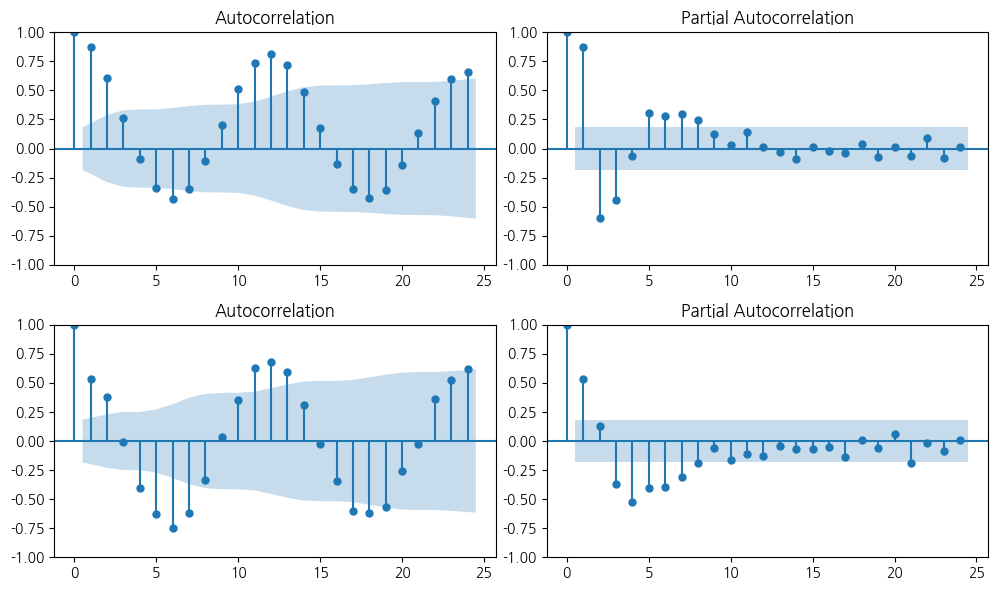

{
  "question": "3-1",
  "method": "ADF: 월별 원자료",
  "H0": "단위근이 존재한다",
  "H1": "단위근이 없다",
  "statistic": 0.275118552926449,
  "p_value": 0.9761736962268875,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "상수항 포함·AIC 시차 선택. 기각이 모든 형태의 정상성 또는 정규성을 입증하지 않는다.",
  "conclusion": "귀무가설을 기각하지 못한다. 월별 원자료에 단위근이 없다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}
{
  "question": "3-1",
  "method": "ADF: 일반 차분",
  "H0": "단위근이 존재한다",
  "H1": "단위근이 없다",
  "statistic": -6.9784986283344335,
  "p_value": 8.308618992272413e-10,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "상수항 포함·AIC 시차 선택. 기각이 모든 형태의 정상성 또는 정규성을 입증하지 않는다.",
  "conclusion": "귀무가설을 기각한다. 일반 차분에 단위근이 없다는 통계적 근거가 있다."
}
{
  "question": "3-1",
  "method": "ADF: 12개월 차분",
  "H0": "단위근이 존재한다",
  "H1": "단위근이 없다",
  "statistic": -3.058058505628123,
  "p_value": 0.029816802201773542,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "상수항 포함·AIC 시차 선택. 기각이 모든 형태의 정상성 또는 정규성을 입증하지 않는다.",
  "conclusion": "귀무가설을 기각한다. 12개월 차분에 단위근이

In [6]:
set_question('3-1')
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
traffic18=load('series.csv');train18=traffic18.value.iloc[:int(len(traffic18)*.8)].interpolate().ffill().bfill()
print({'ADF_raw':adfuller(train18)[1],'ADF_diff':adfuller(train18.diff().dropna())[1],'ADF_seasonal_diff':adfuller(train18.diff(12).dropna())[1]})
fig,axes=plt.subplots(2,2,figsize=(10,6));plot_acf(train18,lags=24,ax=axes[0,0]);plot_pacf(train18,lags=24,ax=axes[0,1]);plot_acf(train18.diff().dropna(),lags=24,ax=axes[1,0]);plot_pacf(train18.diff().dropna(),lags=24,ax=axes[1,1]);plt.tight_layout();plt.show()

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_adf(train18,'월별 원자료')
report_adf(train18.diff().dropna(),'일반 차분')
report_adf(train18.diff(12).dropna(),'12개월 차분')

### 3-2

일반 차분·계절 구조를 고려한 시계열 후보를 최소 3개 설정하시오. 학습 AIC로 비교·선택하고 보류 오차로 후보를 다시 고르지 마시오.

**판단 및 풀이 근거**

3개 비계절 차수에 동일한 계절항 (1,0,0,12)을 결합합니다. 수렴한 후보만 비교하고 test로 차수를 고르지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

       order         AIC  converged
0  (1, 1, 0)  587.450270       True
1  (0, 1, 1)  563.172458       True
2  (1, 1, 1)  565.159291       True
{'order': (0, 1, 1), 'RMSE': 2.393763968880945, 'MAE': 1.917449495865271, 'ADF_train_p': 0.9761736962268875}


/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/root/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self.

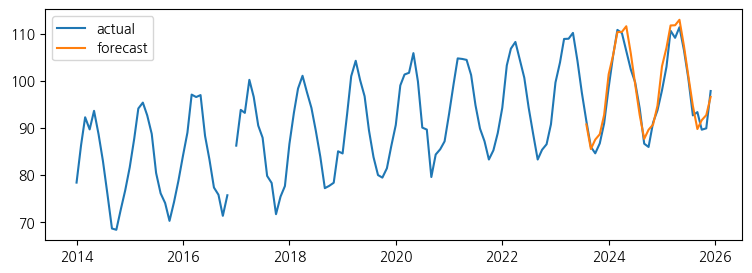

In [7]:
set_question('3-2')
traffic18_model,traffic18_metrics=seasonal_forecast(traffic18,OUT,period=12,orders=[(1,1,0),(0,1,1),(1,1,1)])

### 3-3

선택 모형의 잔차가 정규 분포와 시차 무상관 조건에 부합하는지 조사하시오. 진단 방법과 각각의 가설·통계량·p-value·기각 여부를 제시하고 잔차 그림과 함께 설명하시오.

**판단 및 풀이 근거**

적합 잔차의 정규성은 Shapiro-Wilk, 시차 무상관은 Ljung-Box로 평가한다. 후자는 선택 모형의 비계절·계절 AR/MA 계수 개수를 자유도에서 차감한다.

**계산·해석 상세**

초기 상태 추정의 영향을 줄여 첫 계절을 제외합니다. fitted 잔차 진단이며 관측 잡음의 실제값과 동일하다고 주장하지 않습니다. Ljung-Box model_df는 선택 모형의 AR/MA 계수 수입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

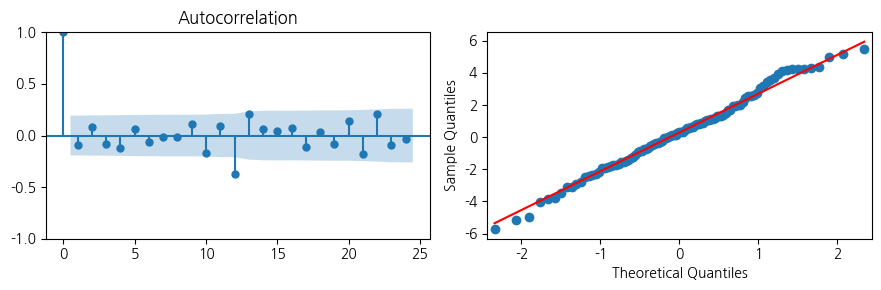

ShapiroResult(statistic=np.float64(0.9903590716687194), pvalue=np.float64(0.674400288579647))
      lb_stat  lb_pvalue
12  26.859914   0.001475
24  49.692799   0.000402
{
  "question": "3-3",
  "method": "Shapiro-Wilk: 월별 예측 모형 잔차",
  "H0": "잔차의 주변 분포가 정규이다",
  "H1": "잔차의 주변 분포가 정규가 아니다",
  "statistic": 0.9903590716687194,
  "p_value": 0.674400288579647,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "적합 잔차의 진단용 p값이며 독립 표본 검정과 같은 확증 해석에 주의한다.",
  "conclusion": "귀무가설을 기각하지 못한다. 월별 예측 모형 잔차가 정규 분포에서 벗어난다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}
{
  "question": "3-3",
  "method": "Ljung-Box: 월별 예측 모형 잔차, lag=12",
  "H0": "lag 1~12의 자기상관이 모두 0이다",
  "H1": "해당 시차 중 하나 이상 자기상관이 0이 아니다",
  "statistic": 26.859914227960118,
  "p_value": 0.0027405636109235606,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "적합한 AR·MA 계수 수를 자유도에서 차감한다. 정규성·등분산 검정과 구분한다.",
  "conclusion": "귀무가설을 기각한다. 월별 예측 모형 잔차에 잔여 시차 의존성이 있다는 통계적 근거가 있다.",
  "df": 10
}
{
  "question": "3-3",
  "method": "Ljung

In [8]:
set_question('3-3')
res18=pd.Series(traffic18_model.resid).iloc[12:]
fig,axes=plt.subplots(1,2,figsize=(9,3));plot_acf(res18,lags=24,ax=axes[0]);sm.qqplot(res18,line='s',ax=axes[1]);plt.tight_layout();plt.show()
print(stats.shapiro(res18));print(sm.stats.acorr_ljungbox(res18,lags=[12,24],model_df=3,return_df=True))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_order=traffic18_model.model.order;_seasonal=traffic18_model.model.seasonal_order
_model_df=_order[0]+_order[2]+_seasonal[0]+_seasonal[2]
report_residuals(res18,'월별 예측 모형 잔차',[12,24],_model_df)

### 3-4

정해진 보류 구간 전체를 한 번에 예측하고 RMSE·MAE를 제시하시오. 실제값이 0에 가까울 때 MAPE를 사용하기 어려운 이유를 설명하시오.

**판단 및 풀이 근거**

예측 결과 CSV는 앞 셀에서 저장했습니다. 누락된 보류 실제값은 오차 집계에서만 제외하며 학습에 보류 값을 사용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [9]:
set_question('3-4')
print(traffic18_metrics);print('합성 교통사고 자료. count 비음수 제약·0값에 대한 MAPE 불안정, 계절 나이브 기준선과 추가 비교 필요.')

{'order': (0, 1, 1), 'RMSE': 2.393763968880945, 'MAE': 1.917449495865271, 'ADF_train_p': 0.9761736962268875}
합성 교통사고 자료. count 비음수 제약·0값에 대한 MAPE 불안정, 계절 나이브 기준선과 추가 비교 필요.
